# Практическая работа № 2. Пайплайн обработки данных и инжиниринг признаков
**Тема проекта:** система анализа и прогнозирования качества воздуха в городах России методами машинного обучения.
**Данные:** «Состояние загрязнения атмосферы в городах России с 2007 года» (Росгидромет, обработка «Если быть точным», CC BY).

Ноутбук рассчитан на запуск в **Google Colab** (Среда выполнения → Выполнить все). При первом запуске в Colab ячейка 1 попросит загрузить файл `data_air_cities_100_v20260617.csv`. Все графики сохраняются в `reports/figures/` и вставляются в отчёт.

Содержание: 2.1 разбиение данных на исходную часть и порции → 2.2 разведочный анализ (EDA) и проверка гипотез → 2.3 проверка идей для признаков → диаграммы C4 и UML (2.5, 2.6).

In [1]:
# 1. Настройка окружения и загрузка исходного файла
import os, sys, json, hashlib, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10, 'axes.titlesize': 11})
SHOW_TITLES = os.environ.get('PR_TITLES', '1') == '1'   # заголовки на рисунках (в отчёте убраны)
FIG = Path(os.environ.get('PR_FIG', 'reports/figures')); FIG.mkdir(parents=True, exist_ok=True)
for p in ['data/raw', 'data/incoming', 'data/interim']:
    Path(p).mkdir(parents=True, exist_ok=True)

RAW = Path('data/raw/data_air_cities_100_v20260617.csv')
if not RAW.exists():
    if 'google.colab' in sys.modules:
        from google.colab import files
        print('Загрузите файл data_air_cities_100_v20260617.csv')
        up = files.upload()
        RAW.write_bytes(up[next(iter(up))])
    else:
        raise FileNotFoundError('Положите исходный CSV в data/raw/')

LEVEL_COLORS = {1: '#FFD966', 2: '#F4A259', 3: '#D1495B', 4: '#7A1F3D'}
LEVEL_NAMES = {1: '1 — низкий', 2: '2 — повышенный', 3: '3 — высокий', 4: '4 — очень высокий'}
results = {}          # сюда складываем числа, которые попадут в отчёт
print('Файл найден:', RAW, RAW.stat().st_size, 'байт')

Файл найден: data/raw/data_air_cities_100_v20260617.csv 1122852 байт


## 2.1. Данные и сценарий их обновления
Набор содержит год наблюдения (`year`), поэтому делим **по времени**: исходная часть — 2007–2017 годы (около 60 % записей), далее четыре порции «новых» данных (выгрузки за 1–2 года). Исходный файл в `data/raw` не изменяется; в репозитории то же самое делает скрипт `src/data/split_batches.py`.

In [2]:
# 2. Разбиение на исходную часть и порции + манифест с контрольными суммами
INITIAL_LAST = 2017
BATCHES = [(2018, 2019), (2020, 2021), (2022, 2023), (2024, 2024)]
SOURCE = 'Росгидромет / ГГО им. Воейкова; обработка «Если быть точным», https://tochno.st/datasets/air_cities (CC BY)'

def sha256(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()

raw = pd.read_csv(RAW, encoding='utf-8-sig', dtype=str)
yr = raw['year'].astype(int)
parts = {Path('data/interim/initial_part.csv'): raw[yr <= INITIAL_LAST]}
for i, (a, b) in enumerate(BATCHES, 1):
    parts[Path(f'data/incoming/batch_{i:02d}.csv')] = raw[(yr >= a) & (yr <= b)]

manifest = [{'file': str(RAW), 'rows': len(raw), 'sha256': sha256(RAW), 'years': f'{yr.min()}–{yr.max()}', 'source': SOURCE}]
for path, part in parts.items():
    part.to_csv(path, index=False, encoding='utf-8')
    manifest.append({'file': str(path), 'rows': len(part), 'sha256': sha256(path),
                     'years': f"{part['year'].astype(int).min()}–{part['year'].astype(int).max()}", 'source': str(RAW)})
assert sum(len(p) for p in parts.values()) == len(raw), 'потеряны или задвоены записи'
Path('data/MANIFEST.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')

split_table = pd.DataFrame(manifest)
split_table['доля, %'] = (split_table['rows'] / len(raw) * 100).round(1)
split_table['sha256 (12 симв.)'] = split_table['sha256'].str[:12]
print(split_table[['file', 'rows', 'доля, %', 'years', 'sha256 (12 симв.)']].to_string(index=False))
results['split'] = split_table[['file', 'rows', 'доля, %', 'years', 'sha256 (12 симв.)']].to_dict('records')

                                      file  rows  доля, %     years sha256 (12 симв.)
data/raw/data_air_cities_100_v20260617.csv  4479    100.0 2007–2024      ceb4a21f203f
             data/interim/initial_part.csv  2748     61.4 2007–2017      39bd26079b8c
                data/incoming/batch_01.csv   496     11.1 2018–2019      45a2286d38b4
                data/incoming/batch_02.csv   499     11.1 2020–2021      a25c74af2e47
                data/incoming/batch_03.csv   490     10.9 2022–2023      880363980c82
                data/incoming/batch_04.csv   246      5.5 2024–2024      d23b7dcda38e


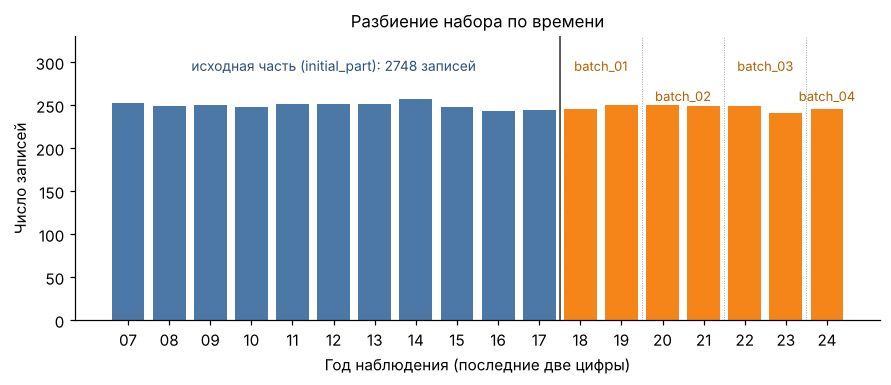

In [3]:
#  Разбиение набора по годам: исходная часть и порции
cnt = raw.groupby(yr).size()
fig, ax = plt.subplots(figsize=(8.2, 3.6))
ax.bar(cnt.index, cnt.values, color=['#4C78A8' if y <= INITIAL_LAST else '#F58518' for y in cnt.index])
ax.set_ylim(0, 330)
ax.set_xticks(cnt.index); ax.set_xticklabels([str(y)[2:] for y in cnt.index])
ax.set_xlabel('Год наблюдения (последние две цифры)'); ax.set_ylabel('Число записей')
ax.text((2007 + INITIAL_LAST) / 2, 290, f'исходная часть (initial_part): {len(parts[Path("data/interim/initial_part.csv")])} записей',
        ha='center', fontsize=9, color='#2B4F76')
for i, (a, b) in enumerate(BATCHES, 1):
    ax.text((a + b) / 2, 255 + (i % 2) * 35, f'batch_{i:02d}', ha='center', fontsize=8.5, color='#B35F00')
    ax.axvline(a - 0.5, color='#999', lw=0.6, ls=':')
ax.axvline(INITIAL_LAST + 0.5, color='#333', lw=1)
if SHOW_TITLES: ax.set_title('Разбиение набора по времени')
plt.tight_layout(); plt.savefig(FIG / 'fig01_split.png', bbox_inches='tight'); plt.show()

## 2.2. Предметный разведочный анализ (только исходная часть, 2007–2017)

In [4]:
# 3. Загрузка исходной части и служебные признаки
df = pd.read_csv('data/interim/initial_part.csv', dtype={'region_oktmo': str, 'city_oktmo': str, 'fias_code': str})
EM = ['air_solid_emissions', 'air_so_emissions', 'air_no_emissions', 'air_co_emissions']
NUM = EM + ['air_population']
RU = {'air_solid_emissions': 'Твёрдые вещества', 'air_so_emissions': 'SO₂', 'air_no_emissions': 'NO₂',
      'air_co_emissions': 'CO', 'air_population': 'Население, тыс. чел.'}
df['city_key'] = df['region'] + ' | ' + df['city']                       # составной ключ города (city_oktmo неуникален)
df['n_st_main'] = df['air_stantions'].str.extract(r'^(\d+)')[0].astype(float)  # число постов основной сети
L = df[df['air_general_level'].isin([1, 2, 3, 4])].copy()               # записи с известным уровнем
L['high'] = (L['air_general_level'] >= 3).astype(int)                    # «высокий/очень высокий»

results['n_rows'] = len(df); results['n_cities'] = int(df['city_key'].nunique()); results['n_regions'] = int(df['region'].nunique())
results['n_labeled'] = len(L)
print('Строк:', len(df), '| городов (по ключу):', results['n_cities'], '| регионов:', results['n_regions'], '| лет:', df.year.nunique())
print('Записей с известным уровнем:', len(L))

Строк: 2748 | городов (по ключу): 301 | регионов: 77 | лет: 11
Записей с известным уровнем: 2393


In [5]:
# Структура набора: смысл, тип, заполненность
MEAN = {
 'year': ('Год наблюдения', 'int'), 'region': ('Регион', 'str'), 'region_oktmo': ('Код ОКТМО региона', 'str'),
 'city': ('Город / населённый пункт', 'str'), 'city_oktmo': ('Код ОКТМО населённого пункта', 'str'),
 'name_with_type': ('Название с типом (г, пгт и др.)', 'str'), 'geo_lat': ('Широта, градусы', 'float'),
 'geo_lon': ('Долгота, градусы', 'float'), 'fias_id': ('Идентификатор ФИАС', 'str'), 'fias_code': ('Код ФИАС', 'str'),
 'air_general_level': ('Общий уровень загрязнения (1–4; −9 — не оценён) — ЦЕЛЬ', 'int'),
 'air_standard_index': ('Вещества с СИ > 10 ПДК', 'str'), 'air_repeatability': ('Наибольшая повторяемость (НП), % и вещество', 'str'),
 'air_qcp': ('Вещества со среднегодовой концентрацией > 1 ПДК', 'str'),
 'air_solid_emissions': ('Выбросы твёрдых веществ, тыс. т', 'float'), 'air_so_emissions': ('Выбросы SO₂, тыс. т', 'float'),
 'air_no_emissions': ('Выбросы NO₂, тыс. т', 'float'), 'air_co_emissions': ('Выбросы CO, тыс. т', 'float'),
 'air_population': ('Численность населения, тыс. чел.', 'float'), 'air_stantions': ('Число станций мониторинга (вид «5+1», «эп»)', 'str')}
struct = pd.DataFrame({'Признак': df.columns[:20]})
struct['Смысл'] = struct['Признак'].map(lambda c: MEAN[c][0]); struct['Тип'] = struct['Признак'].map(lambda c: MEAN[c][1])
struct['Пропусков'] = [int(df[c].isna().sum()) for c in struct['Признак']]
struct['Уникальных'] = [int(df[c].nunique()) for c in struct['Признак']]
print(struct.to_string(index=False))
results['structure'] = struct.to_dict('records')

            Признак                                                  Смысл   Тип  Пропусков  Уникальных
               year                                         Год наблюдения   int          0          11
             region                                                 Регион   str          0          77
       region_oktmo                                      Код ОКТМО региона   str          0          77
               city                               Город / населённый пункт   str          0         297
         city_oktmo                           Код ОКТМО населённого пункта   str          0         283
     name_with_type                        Название с типом (г, пгт и др.)   str         15         281
            geo_lat                                        Широта, градусы float         16         283
            geo_lon                                       Долгота, градусы float         16         283
            fias_id                                     Идентифи

### Целевая переменная

air_general_level
 1    848
 2    446
 3    803
 4    296
-9    355
air_general_level
1    35.4
2    18.6
3    33.6
4    12.4
max/min = 2.86


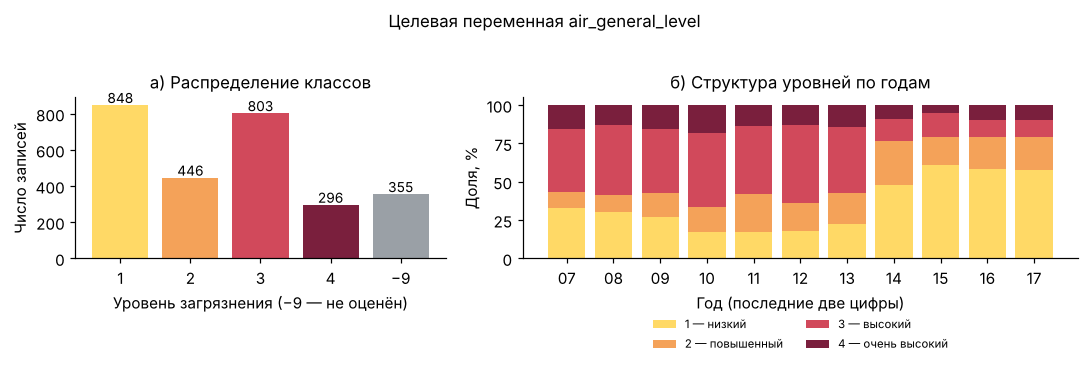

In [6]:
# Рисунок 2. Распределение целевой переменной и динамика по годам
vc = df['air_general_level'].value_counts().reindex([1, 2, 3, 4, -9])
results['target_counts'] = {str(k): int(v) for k, v in vc.items()}
lab = L['air_general_level'].value_counts(normalize=True).sort_index()
results['target_share_labeled'] = {str(k): round(float(v) * 100, 1) for k, v in lab.items()}
results['imbalance_ratio'] = round(float(L['air_general_level'].value_counts().max() / L['air_general_level'].value_counts().min()), 2)
print(vc.to_string()); print((lab * 100).round(1).to_string()); print('max/min =', results['imbalance_ratio'])

fig, axs = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={'width_ratios': [1, 1.5]})
cols = [LEVEL_COLORS[1], LEVEL_COLORS[2], LEVEL_COLORS[3], LEVEL_COLORS[4], '#9AA0A6']
axs[0].bar(['1', '2', '3', '4', '−9'], vc.values, color=cols)
for i, v in enumerate(vc.values): axs[0].text(i, v + 12, int(v), ha='center', fontsize=9)
axs[0].set_xlabel('Уровень загрязнения (−9 — не оценён)'); axs[0].set_ylabel('Число записей'); axs[0].set_title('а) Распределение классов')
sh = pd.crosstab(L['year'], L['air_general_level'], normalize='index') * 100
bottom = np.zeros(len(sh))
for lv in [1, 2, 3, 4]:
    axs[1].bar(sh.index, sh[lv], bottom=bottom, color=LEVEL_COLORS[lv], label=LEVEL_NAMES[lv]); bottom += sh[lv].values
axs[1].set_xticks(sh.index); axs[1].set_xticklabels([str(y)[2:] for y in sh.index])
axs[1].set_xlabel('Год (последние две цифры)'); axs[1].set_ylabel('Доля, %'); axs[1].set_title('б) Структура уровней по годам')
axs[1].legend(fontsize=7.5, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.30), frameon=False)
if SHOW_TITLES: plt.suptitle('Целевая переменная air_general_level', y=1.02, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / 'fig02_target.png', bbox_inches='tight'); plt.show()

### Качество данных: пропуски, дубликаты, невозможные значения, выбросы

air_stantions              0.0
name_with_type             0.5
geo_lon                    0.6
geo_lat                    0.6
fias_code                  1.0
fias_id                    1.0
n_st_main                  1.3
air_population             4.8
air_general_level (−9)    12.9
air_no_emissions          19.3
air_co_emissions          19.3
air_solid_emissions       19.5
air_so_emissions          20.1


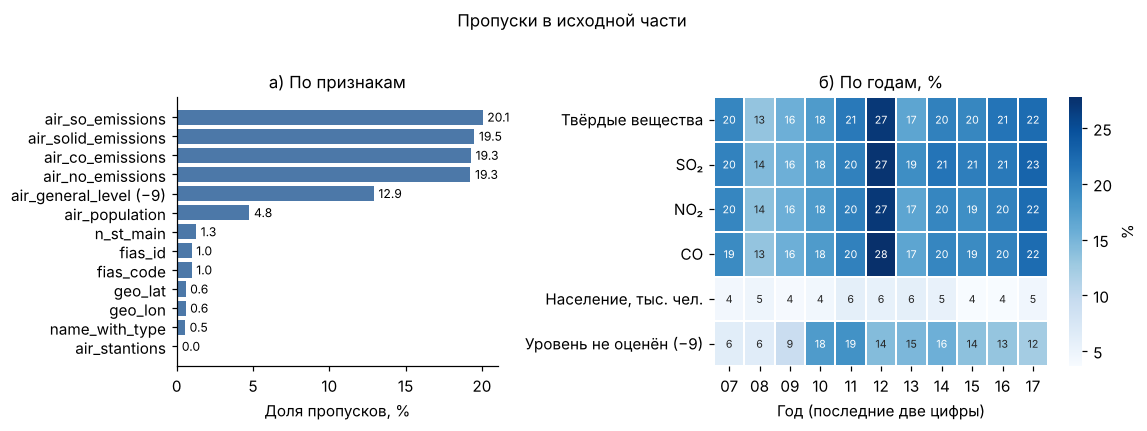

In [7]:
# Рисунок 3. Пропуски по признакам и по годам
miss = (df.isna().mean() * 100)
miss['air_general_level (−9)'] = (df['air_general_level'] == -9).mean() * 100
miss = miss[miss > 0].sort_values()
results['missing_pct'] = {k: round(float(v), 1) for k, v in miss.items()}
print(miss.round(1).to_string())

by_year = df.groupby('year')[NUM].apply(lambda g: g.isna().mean() * 100)
by_year['Уровень не оценён (−9)'] = df.groupby('year')['air_general_level'].apply(lambda s: (s == -9).mean() * 100)
by_year = by_year.rename(columns=RU)
results['missing_by_year'] = by_year.round(1).to_dict('index')

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8), gridspec_kw={'width_ratios': [1, 1.3]})
axs[0].barh(miss.index, miss.values, color='#4C78A8'); axs[0].set_xlabel('Доля пропусков, %'); axs[0].set_title('а) По признакам')
for i, v in enumerate(miss.values): axs[0].text(v + 0.3, i, f'{v:.1f}', va='center', fontsize=8)
sns.heatmap(by_year.T, ax=axs[1], cmap='Blues', annot=True, fmt='.0f', annot_kws={'size': 7}, cbar_kws={'label': '%'}, linewidths=0.3)
axs[1].set_xticklabels([str(y)[2:] for y in by_year.index], rotation=0); axs[1].set_xlabel('Год (последние две цифры)'); axs[1].set_title('б) По годам, %')
if SHOW_TITLES: plt.suptitle('Пропуски в исходной части', y=1.02, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / 'fig03_missing.png', bbox_inches='tight'); plt.show()

In [8]:
# Дубликаты и невозможные значения
chk = []
chk.append(('Полные дубликаты строк', int(df.duplicated().sum())))
chk.append(('Дубликаты по (city_oktmo, year)', int(df.duplicated(['city_oktmo', 'year'], keep=False).sum())))
chk.append(('Дубликаты по (регион, город, год)', int(df.duplicated(['city_key', 'year']).sum())))
chk.append(('Отрицательные значения (выбросы, население)', int((df[NUM] < 0).sum().sum())))
chk.append(('Население = 0', int((df['air_population'] == 0).sum())))
chk.append(('Нулевые значения выбросов', int((df[EM] == 0).sum().sum())))
chk.append(('Уровень вне {−9, 1, 2, 3, 4}', int((~df['air_general_level'].isin([-9, 1, 2, 3, 4])).sum())))
chk.append(('Координаты вне границ РФ (широта 41–82, долгота 19–180)', int((df['geo_lat'].notna() & ~df['geo_lat'].between(41, 82) | df['geo_lon'].notna() & ~df['geo_lon'].between(19, 180)).sum())))
chk.append(('Длина city_oktmo не 8 и не 11', int((~df['city_oktmo'].str.len().isin([8, 11])).sum())))
chk.append(('city_oktmo длиной 8 (код региона вместо города)', int((df['city_oktmo'].str.len() == 8).sum())))
chk.append(('air_stantions не по шаблону «N», «N+M», «N+эп», «эп»', int((~df['air_stantions'].fillna('1').str.match(r'^(\d+(\+(\d+|эп))?|эп)$')).sum())))
chk.append(('Выбросы SO₂ > 1000 тыс. т (проверка на правдоподобие)', int((df['air_so_emissions'] > 1000).sum())))
chk_df = pd.DataFrame(chk, columns=['Проверка', 'Записей'])
print(chk_df.to_string(index=False)); results['checks'] = chk_df.to_dict('records')
dup = df[df.duplicated(['city_oktmo', 'year'], keep=False)].sort_values(['city_oktmo', 'year'])
print(dup[['year', 'region', 'city', 'city_oktmo', 'air_population']].head(6).to_string(index=False))
print('Крупнейшие значения SO₂:'); print(df.nlargest(4, 'air_so_emissions')[['year', 'city', 'air_so_emissions']].to_string(index=False))

                                               Проверка  Записей
                                 Полные дубликаты строк        0
                        Дубликаты по (city_oktmo, year)       37
                      Дубликаты по (регион, город, год)        0
            Отрицательные значения (выбросы, население)        0
                                          Население = 0        0
                              Нулевые значения выбросов       10
                           Уровень вне {−9, 1, 2, 3, 4}        0
Координаты вне границ РФ (широта 41–82, долгота 19–180)        0
                          Длина city_oktmo не 8 и не 11        0
        city_oktmo длиной 8 (код региона вместо города)       58
   air_stantions не по шаблону «N», «N+M», «N+эп», «эп»       29
  Выбросы SO₂ > 1000 тыс. т (проверка на правдоподобие)       11
 year              region              city  city_oktmo  air_population
 2007 Сахалинская область НОВОАЛЕКСАНДРОВСК 64701000001            10.7
 2007 Сахал

Доля выбросов по правилу 1.5·IQR, %: {'Твёрдые вещества': 13.2, 'SO₂': 12.4, 'NO₂': 8.2, 'CO': 11.0, 'Население, тыс. чел.': 7.2}
                      count   mean    std  min    50%     95%      max
air_solid_emissions  2212.0    4.5    7.6  0.0    1.5    21.4     70.7
air_so_emissions     2197.0   15.9  133.2  0.0    1.2    33.6   1950.5
air_no_emissions     2219.0    8.0   19.1  0.0    3.9    27.9    728.9
air_co_emissions     2218.0   27.0   56.5  0.0    9.4   105.8    797.4
air_population       2617.0  296.8  838.1  0.2  113.9  1016.3  12380.7


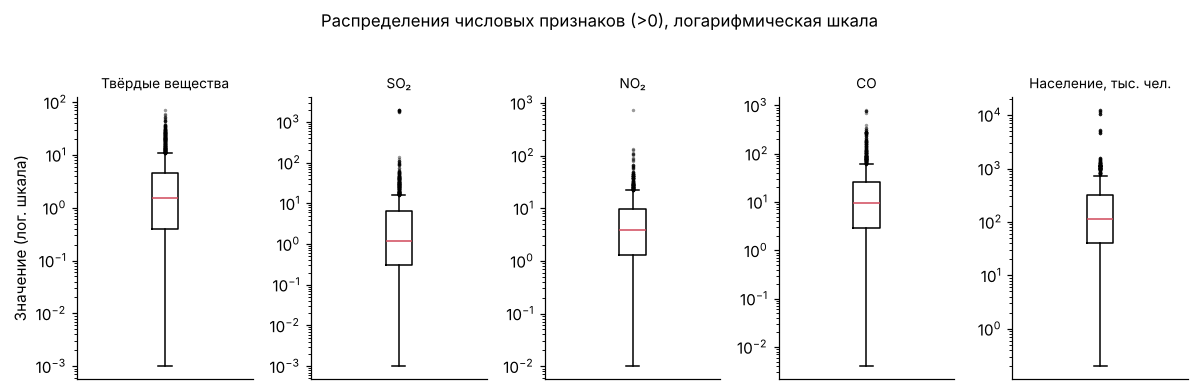

In [9]:
# Рисунок 4. Выбросы и население: логарифмические ящики (проверка выбросов)
fig, axs = plt.subplots(1, 5, figsize=(11, 3.4))
out = {}
for ax, c in zip(axs, NUM):
    s = df[c].dropna(); s = s[s > 0]
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    out[c] = round(float(((s > q3 + 1.5 * iqr)).mean() * 100), 1)
    ax.boxplot(s, vert=True, flierprops=dict(marker='.', markersize=2.5, alpha=.4), medianprops=dict(color='#D1495B'))
    ax.set_yscale('log'); ax.set_xticks([]); ax.set_title(RU[c], fontsize=9)
axs[0].set_ylabel('Значение (лог. шкала)')
if SHOW_TITLES: plt.suptitle('Распределения числовых признаков (>0), логарифмическая шкала', y=1.03, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / 'fig04_outliers.png', bbox_inches='tight'); plt.show()
results['iqr_outliers_pct'] = {RU[k]: v for k, v in out.items()}
print('Доля выбросов по правилу 1.5·IQR, %:', results['iqr_outliers_pct'])
print(df[NUM].describe(percentiles=[.5, .95]).round(1).T.to_string())

### Распределения признаков и связь с целевой переменной

                   air_solid_emissions  air_so_emissions  air_no_emissions  air_co_emissions  air_population
air_general_level                                                                                           
1                                  0.7               0.6               2.6               5.7            76.7
2                                  1.3               0.8               3.9              11.3           152.6
3                                  2.2               2.1               6.5              16.6           244.5
4                                  4.2               3.9               6.6              13.6           206.4


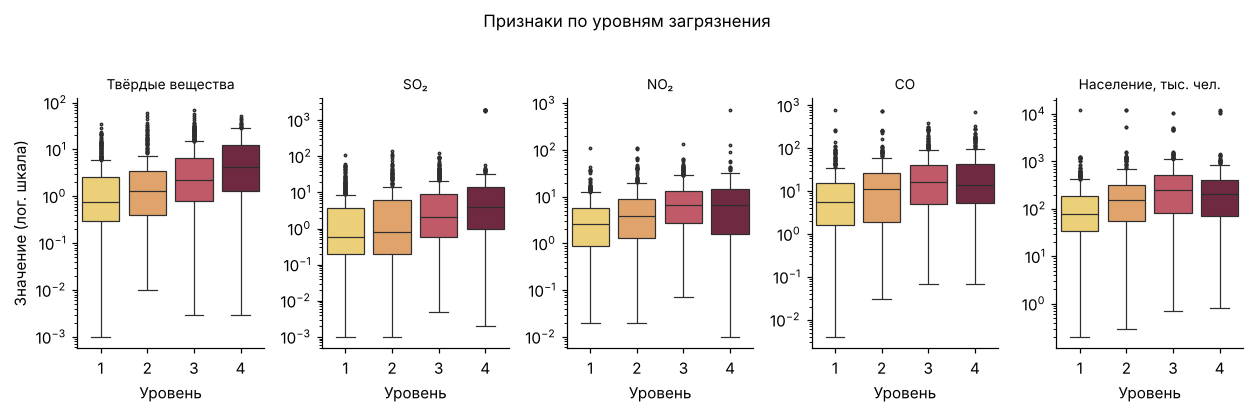

In [10]:
# Рисунок 5. Выбросы и население по уровням загрязнения
fig, axs = plt.subplots(1, 5, figsize=(11.5, 3.6), sharex=False)
for ax, c in zip(axs, NUM):
    d = L[L[c] > 0]
    sns.boxplot(data=d, x='air_general_level', y=c, palette=[LEVEL_COLORS[i] for i in [1, 2, 3, 4]], ax=ax,
                fliersize=1.5, linewidth=0.8)
    ax.set_yscale('log'); ax.set_xlabel('Уровень'); ax.set_ylabel(''); ax.set_title(RU[c], fontsize=9)
axs[0].set_ylabel('Значение (лог. шкала)')
if SHOW_TITLES: plt.suptitle('Признаки по уровням загрязнения', y=1.03, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / 'fig05_by_level.png', bbox_inches='tight'); plt.show()
med = L.groupby('air_general_level')[NUM].median().round(1); print(med.to_string())
results['medians_by_level'] = med.rename(columns=RU).to_dict('index')

                      Твёрдые вещества   SO₂   NO₂    CO  Население, тыс. чел.  Станций (осн.)   Год  Уровень (цель)
Твёрдые вещества                  1.00  0.72  0.51  0.41                  0.26            0.32 -0.11            0.32
SO₂                               0.72  1.00  0.56  0.41                  0.27            0.37 -0.13            0.27
NO₂                               0.51  0.56  1.00  0.78                  0.69            0.63 -0.03            0.28
CO                                0.41  0.41  0.78  1.00                  0.69            0.59  0.10            0.26
Население, тыс. чел.              0.26  0.27  0.69  0.69                  1.00            0.77  0.04            0.29
Станций (осн.)                    0.32  0.37  0.63  0.59                  0.77            1.00  0.03            0.35
Год                              -0.11 -0.13 -0.03  0.10                  0.04            0.03  1.00           -0.28
Уровень (цель)                    0.32  0.27  0.28  0.26        

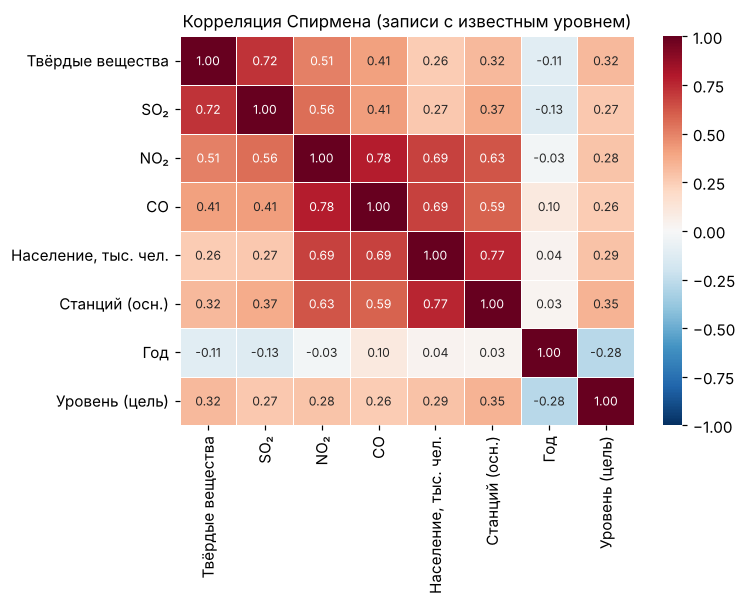

In [11]:
# Рисунок 6. Корреляции между признаками (Спирмен)
cols = NUM + ['n_st_main', 'year', 'air_general_level']
corr = L[cols].corr(method='spearman')
names = [RU[c] for c in NUM] + ['Станций (осн.)', 'Год', 'Уровень (цель)']
corr.index = names; corr.columns = names
results['corr'] = corr.round(2).to_dict('index')
fig, ax = plt.subplots(figsize=(7, 5.6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax, annot_kws={'size': 8}, linewidths=.4)
if SHOW_TITLES: ax.set_title('Корреляция Спирмена (записи с известным уровнем)')
plt.tight_layout(); plt.savefig(FIG / 'fig06_corr.png', bbox_inches='tight'); plt.show()
print(corr.round(2).to_string())

### Признаки, недоступные в момент прогноза или раскрывающие цель
Общий уровень загрязнения рассчитывается по ИЗА, СИ и НП. Поэтому поля `air_standard_index`, `air_repeatability` и `air_qcp` за **тот же год** содержат компоненты расчёта цели.

                   air_qcp (среднегодовые > 1 ПДК)  air_standard_index (СИ > 10 ПДК)  air_repeatability (НП)
air_general_level                                                                                           
1                                             50.5                               0.7                     0.9
2                                             95.7                              13.2                     4.0
3                                            100.0                              18.6                    14.1
4                                             99.3                              59.5                    26.4


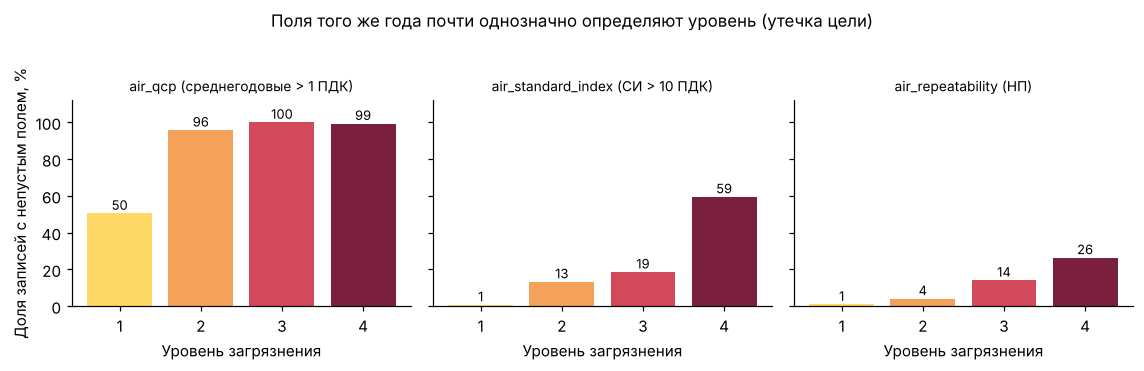

In [12]:
# Рисунок 7. Утечка цели: доля записей с непустыми «веществами» по уровням
leak = pd.DataFrame({
    'air_qcp (среднегодовые > 1 ПДК)': L['air_qcp'].ne('No substance'),
    'air_standard_index (СИ > 10 ПДК)': L['air_standard_index'].ne('No substance'),
    'air_repeatability (НП)': L['air_repeatability'].ne('No substance')}).groupby(L['air_general_level']).mean() * 100
results['leakage_pct'] = leak.round(1).to_dict('index')
print(leak.round(1).to_string())
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.2), sharey=True)
for ax, c in zip(axs, leak.columns):
    ax.bar(leak.index.astype(str), leak[c], color=[LEVEL_COLORS[i] for i in leak.index])
    for i, v in enumerate(leak[c]): ax.text(i, v + 2, f'{v:.0f}', ha='center', fontsize=8.5)
    ax.set_title(c, fontsize=9); ax.set_xlabel('Уровень загрязнения'); ax.set_ylim(0, 112)
axs[0].set_ylabel('Доля записей с непустым полем, %')
if SHOW_TITLES: plt.suptitle('Поля того же года почти однозначно определяют уровень (утечка цели)', y=1.04, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / 'fig07_leakage.png', bbox_inches='tight'); plt.show()

### Гипотезы
**H1.** Чем больше промышленные выбросы города, тем выше уровень загрязнения.  
**H2.** В крупных городах уровень загрязнения выше, чем в малых.  
**H3.** В 2014 году после смены нормативов (ПДК формальдегида) доля городов с уровнем 3–4 резко снизилась (структурный сдвиг цели).  
**H4.** Уровень загрязнения города устойчив во времени: в следующем году он чаще всего тот же или отличается на один уровень.  
**H5.** Число станций мониторинга связано с уровнем (возможный эффект полноты наблюдений, а не реального воздуха).

air_solid_emissions    rho=+0.321  p=2.8e-50  n=2042
air_so_emissions       rho=+0.268  p=8.6e-35  n=2035
air_no_emissions       rho=+0.282  p=1.1e-38  n=2047
air_co_emissions       rho=+0.257  p=2.5e-32  n=2047
air_population         rho=+0.294  p=9.0e-48  n=2343
n_st_main              rho=+0.349  p=2.2e-69  n=2392
{'share_big': 64.9, 'share_small': 38.7, 'chi2': 143.7, 'p': 4.037647493176616e-33}


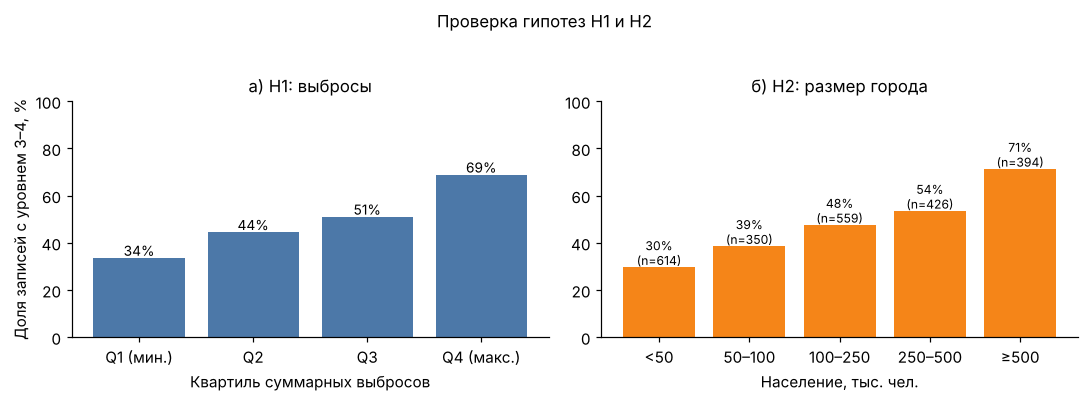

In [13]:
# H1 и H2: Спирмен + доля высокого уровня по группам
h = {}
for c in NUM + ['n_st_main']:
    s = L[[c, 'air_general_level']].dropna()
    rho, p = stats.spearmanr(s[c], s['air_general_level'])
    h[c] = {'rho': round(float(rho), 3), 'p': float(p), 'n': int(len(s))}
results['H1_H2_H5_spearman'] = h
for c, v in h.items(): print(f"{c:22s} rho={v['rho']:+.3f}  p={v['p']:.1e}  n={v['n']}")

# Рисунок 8. Доля уровней 3–4 по квартилям выбросов и по группам населения
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
tot = L[EM].sum(axis=1, min_count=1)
q = pd.qcut(tot.rank(method='first'), 4, labels=['Q1 (мин.)', 'Q2', 'Q3', 'Q4 (макс.)'])
g = L.groupby(q)['high'].mean() * 100
axs[0].bar(g.index.astype(str), g.values, color='#4C78A8')
for i, v in enumerate(g.values): axs[0].text(i, v + 1, f'{v:.0f}%', ha='center', fontsize=9)
axs[0].set_ylim(0, 100); axs[0].set_ylabel('Доля записей с уровнем 3–4, %'); axs[0].set_xlabel('Квартиль суммарных выбросов'); axs[0].set_title('а) H1: выбросы')
bins = [0, 50, 100, 250, 500, 1e6]; lbl = ['<50', '50–100', '100–250', '250–500', '≥500']
pg = pd.cut(L['air_population'], bins, labels=lbl)
g2 = L.groupby(pg)['high'].mean() * 100; n2 = L.groupby(pg)['high'].size()
axs[1].bar(g2.index.astype(str), g2.values, color='#F58518')
for i, (v, n) in enumerate(zip(g2.values, n2.values)): axs[1].text(i, v + 1, f'{v:.0f}%\n(n={n})', ha='center', fontsize=8)
axs[1].set_ylim(0, 100); axs[1].set_xlabel('Население, тыс. чел.'); axs[1].set_title('б) H2: размер города')
results['H1_quartiles_pct'] = {str(k): round(float(v), 1) for k, v in g.items()}
results['H2_pop_groups_pct'] = {str(k): round(float(v), 1) for k, v in g2.items()}
if SHOW_TITLES: plt.suptitle('Проверка гипотез H1 и H2', y=1.03, fontsize=11)
plt.tight_layout(); plt.savefig(FIG / 'fig08_h1_h2.png', bbox_inches='tight'); plt.show()
big = L[L['air_population'] > 300]['high']; small = L[L['air_population'] <= 300]['high']
chi = stats.chi2_contingency(pd.crosstab(L['air_population'] > 300, L['high']))
results['H2_chi2'] = {'share_big': round(float(big.mean() * 100), 1), 'share_small': round(float(small.mean() * 100), 1), 'chi2': round(float(chi[0]), 1), 'p': float(chi[1])}
print(results['H2_chi2'])

{'before_pct': 59.6, 'after_pct': 21.4, 'n_before': 1537, 'n_after': 856, 'chi2': 321.8, 'p': 5.782733816866561e-72, 'by_year': {2007: 57.0, 2008: 58.4, 2009: 57.3, 2010: 66.2, 2011: 58.0, 2012: 63.9, 2013: 57.2, 2014: 23.5, 2015: 20.6, 2016: 20.9, 2017: 20.6}}


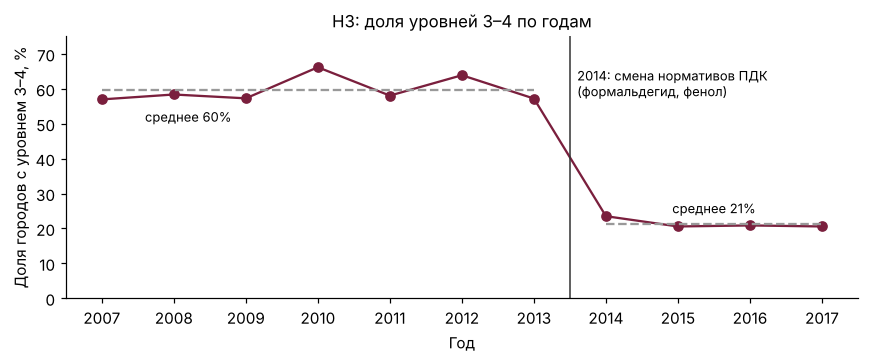

In [14]:
# H3: структурный сдвиг 2014 года
yr_hi = L.groupby('year')['high'].mean() * 100
before = L[L['year'] <= 2013]['high']; after = L[L['year'] >= 2014]['high']
chi3 = stats.chi2_contingency(pd.crosstab(L['year'] >= 2014, L['high']))
results['H3'] = {'before_pct': round(float(before.mean() * 100), 1), 'after_pct': round(float(after.mean() * 100), 1),
                 'n_before': int(len(before)), 'n_after': int(len(after)), 'chi2': round(float(chi3[0]), 1), 'p': float(chi3[1]),
                 'by_year': {int(k): round(float(v), 1) for k, v in yr_hi.items()}}
print(results['H3'])
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(yr_hi.index, yr_hi.values, marker='o', color='#7A1F3D')
ax.hlines(before.mean() * 100, 2007, 2013, colors='#999', ls='--'); ax.hlines(after.mean() * 100, 2014, 2017, colors='#999', ls='--')
ax.axvline(2013.5, color='#333', lw=1)
ax.text(2013.6, 66, '2014: смена нормативов ПДК\n(формальдегид, фенол)', fontsize=8.5, va='top')
ax.text(2008.2, before.mean() * 100 - 9, f'среднее {before.mean()*100:.0f}%', fontsize=8.5, ha='center')
ax.text(2015.5, after.mean() * 100 + 3, f'среднее {after.mean()*100:.0f}%', fontsize=8.5, ha='center')
ax.set_ylim(0, 75); ax.set_xticks(yr_hi.index); ax.set_xlabel('Год'); ax.set_ylabel('Доля городов с уровнем 3–4, %')
if SHOW_TITLES: ax.set_title('H3: доля уровней 3–4 по годам')
plt.tight_layout(); plt.savefig(FIG / 'fig09_h3.png', bbox_inches='tight'); plt.show()

2106 пар; тот же уровень: 72.4 %; в пределах ±1: 97.3 %


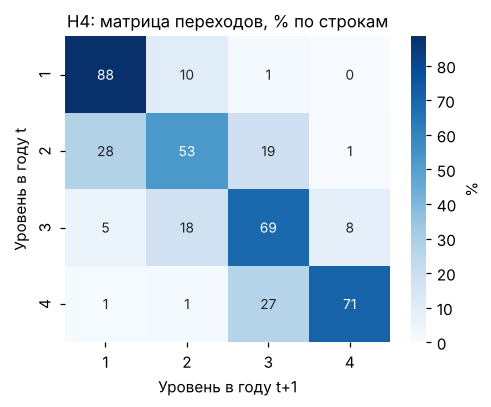

In [15]:
# H4: устойчивость уровня во времени (матрица переходов t -> t+1)
s = df.sort_values(['city_key', 'year']).copy()
s['next_level'] = s.groupby('city_key')['air_general_level'].shift(-1)
s['next_year'] = s.groupby('city_key')['year'].shift(-1)
t = s[(s['next_year'] == s['year'] + 1) & s['air_general_level'].isin([1, 2, 3, 4]) & s['next_level'].isin([1, 2, 3, 4])]
tm = pd.crosstab(t['air_general_level'].astype(int), t['next_level'].astype(int), normalize='index') * 100
same = float((t['air_general_level'] == t['next_level']).mean() * 100)
pm1 = float(((t['air_general_level'] - t['next_level']).abs() <= 1).mean() * 100)
results['H4'] = {'pairs': int(len(t)), 'same_pct': round(same, 1), 'within1_pct': round(pm1, 1), 'matrix': tm.round(1).to_dict('index')}
print(results['H4']['pairs'], 'пар; тот же уровень:', round(same, 1), '%; в пределах ±1:', round(pm1, 1), '%')
fig, ax = plt.subplots(figsize=(4.6, 3.8))
sns.heatmap(tm, annot=True, fmt='.0f', cmap='Blues', ax=ax, cbar_kws={'label': '%'}, annot_kws={'size': 9})
if SHOW_TITLES: ax.set_xlabel('Уровень в году t+1'); ax.set_ylabel('Уровень в году t'); ax.set_title('H4: матрица переходов, % по строкам')
plt.tight_layout(); plt.savefig(FIG / 'fig10_h4.png', bbox_inches='tight'); plt.show()

In [16]:
# H5: число станций и размер города (проверка искажения)
s5 = L[['n_st_main', 'air_population', 'air_general_level']].dropna()
rho_all = stats.spearmanr(s5['n_st_main'], s5['air_general_level'])
terc = pd.qcut(s5['air_population'], 3, labels=['малые', 'средние', 'крупные'])
within = {str(k): round(float(stats.spearmanr(g['n_st_main'], g['air_general_level'])[0]), 3) for k, g in s5.groupby(terc)}
rho_sp = stats.spearmanr(s5['n_st_main'], s5['air_population'])
results['H5'] = {'rho_all': round(float(rho_all[0]), 3), 'p': float(rho_all[1]), 'within_terciles': within, 'rho_stations_population': round(float(rho_sp[0]), 3)}
print(results['H5'])

{'rho_all': 0.337, 'p': 2.130728672874265e-63, 'within_terciles': {'малые': 0.346, 'средние': 0.147, 'крупные': 0.249}, 'rho_stations_population': 0.766}


## 2.6. Проверка идей для признаков
Для плана признаков проверяем, как кандидаты, рассчитанные по году *t*, связаны с уровнем в году *t+1* (ранговая корреляция Спирмена на исходной части). Использованы только значения, известные в момент прогноза.

       feature                         Описание  rho с уровнем t+1    n
    level_lag1         Уровень в году t (лаг 1)              0.841 2106
 high_share_3y Доля лет с уровнем 3–4 за 3 года              0.765 2116
         n_qcp Число веществ > 1 ПДК (в году t)              0.681 2128
     n_st_main      Число станций основной сети              0.324 2128
    emis_total        Суммарные выбросы, тыс. т              0.303 1846
       log_pop               log(1 + население)              0.272 2090
air_population             Население (исходное)              0.272 2090
  emis_per_cap        Выбросы на 1 тыс. жителей              0.129 1845
   emis_growth         Годовой прирост выбросов              0.012 1585


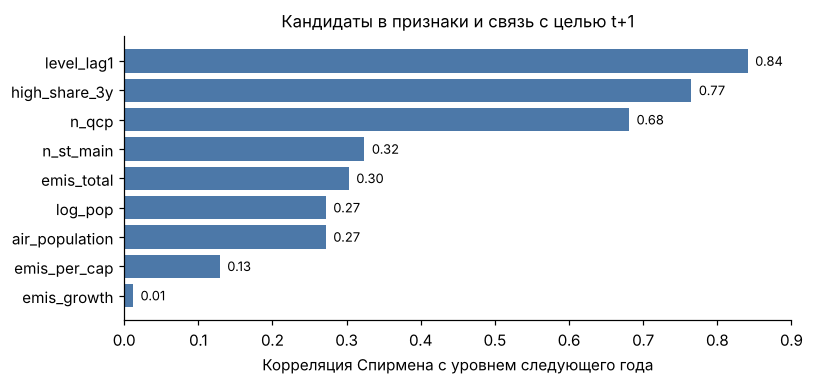

In [17]:
# Кандидаты в признаки и их связь с уровнем следующего года
d = df.sort_values(['city_key', 'year']).copy()
g = d.groupby('city_key')
d['target_next'] = g['air_general_level'].shift(-1)
d['gap'] = g['year'].shift(-1) - d['year']
d['level_lag1'] = d['air_general_level'].where(d['air_general_level'] > 0)
d['emis_total'] = d[EM].sum(axis=1, min_count=1)
d['emis_per_cap'] = d['emis_total'] / d['air_population']
d['emis_prev'] = d.groupby('city_key')['emis_total'].shift(1)
d['emis_growth'] = (d['emis_total'] - d['emis_prev']) / d['emis_prev'].replace(0, np.nan)
d['n_qcp'] = d['air_qcp'].map(lambda x: 0 if x == 'No substance' else len([p for p in str(x).replace(' ', '').split(',') if p]))
d['log_pop'] = np.log1p(d['air_population'])
d['hi_flag'] = np.where(d['air_general_level'] > 0, (d['air_general_level'] >= 3).astype(float), np.nan)
d['high_share_3y'] = d.groupby('city_key')['hi_flag'].transform(lambda s: s.rolling(3, min_periods=1).mean())
d['sulfur_per_cap'] = d['air_so_emissions'] / d['air_population']
ok = d[(d['gap'] == 1) & d['target_next'].isin([1, 2, 3, 4])]
cand = {'level_lag1': 'Уровень в году t (лаг 1)', 'high_share_3y': 'Доля лет с уровнем 3–4 за 3 года',
        'emis_total': 'Суммарные выбросы, тыс. т', 'emis_per_cap': 'Выбросы на 1 тыс. жителей',
        'emis_growth': 'Годовой прирост выбросов', 'n_qcp': 'Число веществ > 1 ПДК (в году t)',
        'log_pop': 'log(1 + население)', 'n_st_main': 'Число станций основной сети', 'air_population': 'Население (исходное)'}
rows = []
for c, name in cand.items():
    sub = ok[[c, 'target_next']].replace([np.inf, -np.inf], np.nan).dropna()
    rho, p = stats.spearmanr(sub[c], sub['target_next'])
    rows.append((c, name, round(float(rho), 3), int(len(sub))))
fp = pd.DataFrame(rows, columns=['feature', 'Описание', 'rho с уровнем t+1', 'n']).sort_values('rho с уровнем t+1', ascending=False)
print(fp.to_string(index=False)); results['feature_check'] = fp.to_dict('records')
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(fp['feature'][::-1], fp['rho с уровнем t+1'][::-1], color='#4C78A8')
for i, v in enumerate(fp['rho с уровнем t+1'][::-1]): ax.text(v + 0.01, i, f'{v:.2f}', va='center', fontsize=8.5)
ax.set_xlim(0, 0.9); ax.set_xlabel('Корреляция Спирмена с уровнем следующего года')
if SHOW_TITLES: ax.set_title('Кандидаты в признаки и связь с целью t+1')
plt.tight_layout(); plt.savefig(FIG / 'fig11_features.png', bbox_inches='tight'); plt.show()

In [18]:
Path('reports').mkdir(exist_ok=True)
def _j(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    return str(o)
Path('reports/results.json').write_text(json.dumps(results, ensure_ascii=False, indent=1, default=_j), encoding='utf-8')
print('results.json сохранён; ключи:', list(results))

results.json сохранён; ключи: ['split', 'n_rows', 'n_cities', 'n_regions', 'n_labeled', 'structure', 'target_counts', 'target_share_labeled', 'imbalance_ratio', 'missing_pct', 'missing_by_year', 'checks', 'iqr_outliers_pct', 'medians_by_level', 'corr', 'leakage_pct', 'H1_H2_H5_spearman', 'H1_quartiles_pct', 'H2_pop_groups_pct', 'H2_chi2', 'H3', 'H4', 'H5', 'feature_check']


## 2.5–2.6. Диаграммы архитектуры и пайплайна (C4 и UML)
Диаграммы строятся кодом (Graphviz и matplotlib) и сохраняются в `reports/figures/`.

In [19]:
# Вспомогательная функция: рендер DOT-диаграммы в PNG (нужен Graphviz; в Colab установлен)
from IPython.display import Image, display
def render_dot(name, dot_src):
    f = FIG / f'{name}.dot'; f.write_text(dot_src, encoding='utf-8')
    subprocess.run(['dot', '-Tpng', '-Gdpi=200', str(f), '-o', str(FIG / f'{name}.png')], check=True)
    display(Image(str(FIG / f'{name}.png')))
FONT = 'Liberation Sans, DejaVu Sans, Arial'

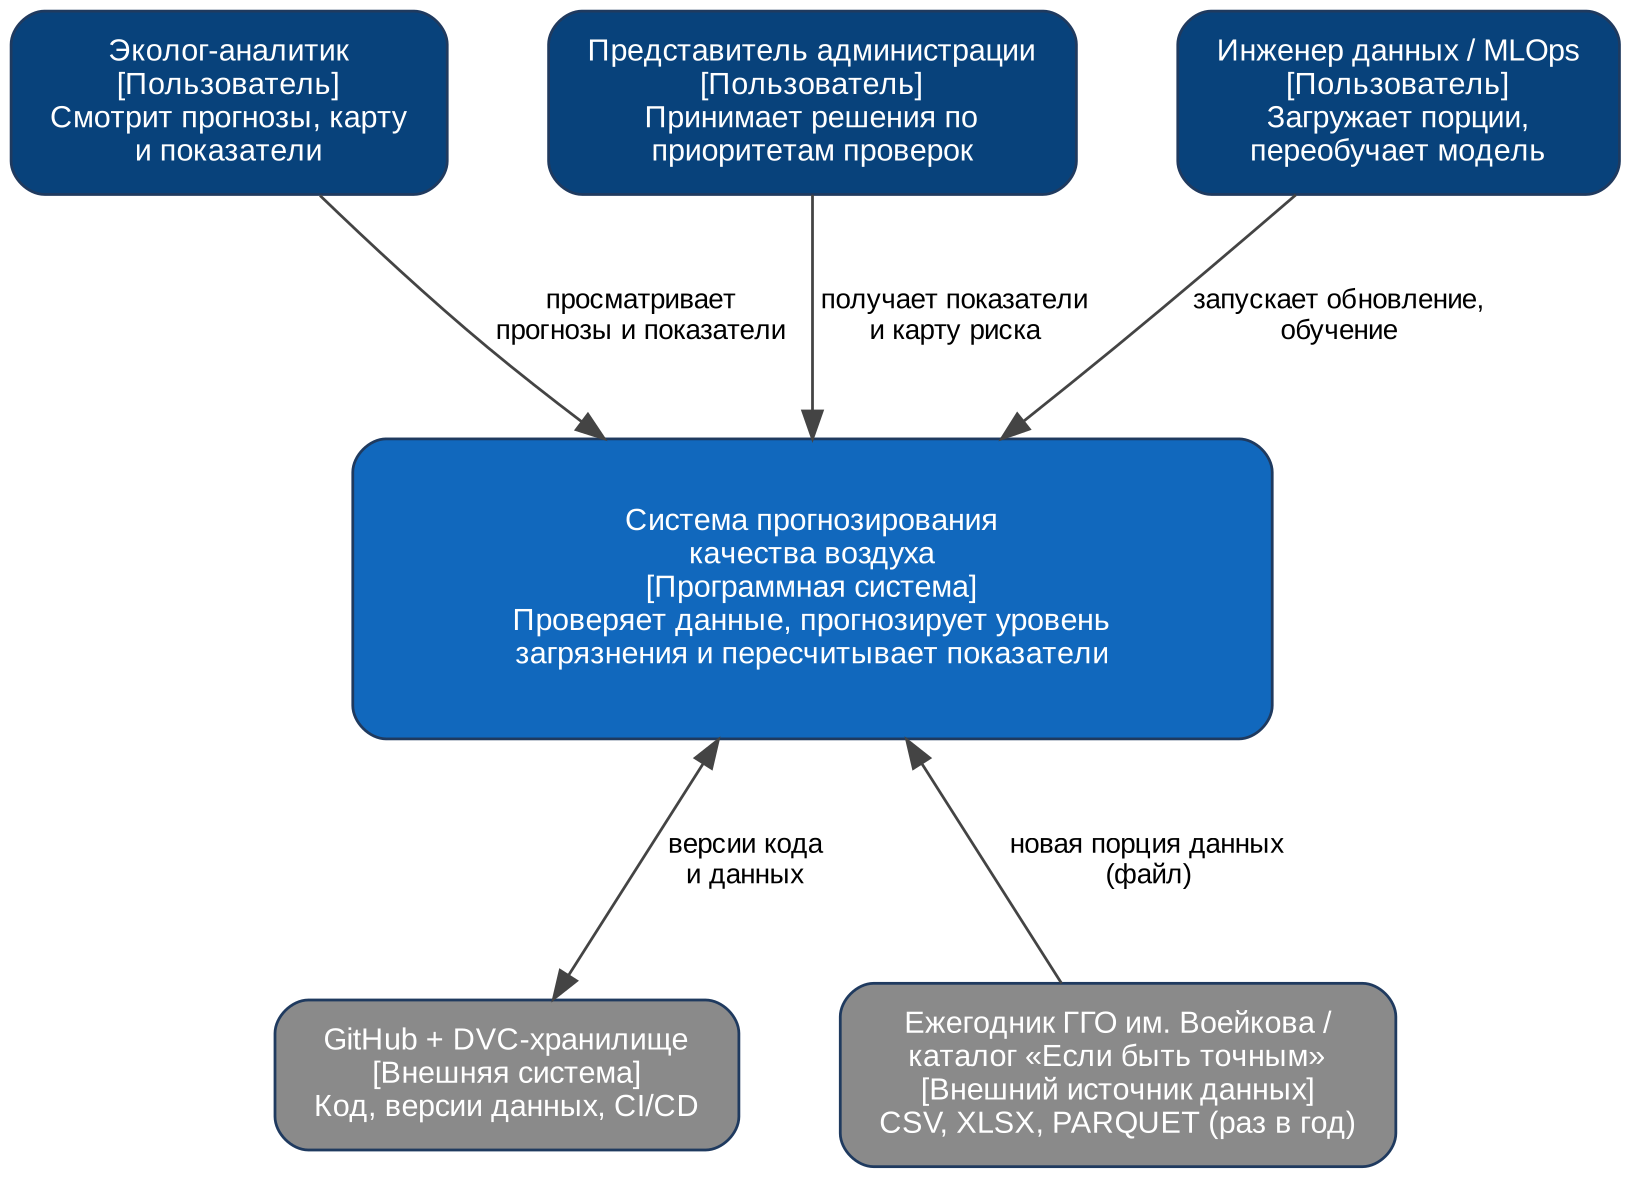

In [20]:
# Рисунок 12. C4, уровень 1: контекст системы
ctx = '''digraph G { rankdir=TB; nodesep=0.5; ranksep=0.9; dpi=200;
 node [shape=box, style="rounded,filled", fontname="Liberation Sans", fontsize=11, margin="0.2,0.12", color="#1F3A5F", fontcolor=white];
 edge [fontname="Liberation Sans", fontsize=10, color="#444444"];
 analyst [label="Эколог-аналитик\n[Пользователь]\nСмотрит прогнозы, карту\nи показатели", fillcolor="#08427B"];
 lpr [label="Представитель администрации\n[Пользователь]\nПринимает решения по\nприоритетам проверок", fillcolor="#08427B"];
 dev [label="Инженер данных / MLOps\n[Пользователь]\nЗагружает порции,\nпереобучает модель", fillcolor="#08427B"];
 sys [label="Система прогнозирования\nкачества воздуха\n[Программная система]\nПроверяет данные, прогнозирует уровень\nзагрязнения и пересчитывает показатели", fillcolor="#1168BD", width=4.6, height=1.5];
 ggo [label="Ежегодник ГГО им. Воейкова /\nкаталог «Если быть точным»\n[Внешний источник данных]\nCSV, XLSX, PARQUET (раз в год)", fillcolor="#8A8A8A"];
 gh [label="GitHub + DVC-хранилище\n[Внешняя система]\nКод, версии данных, CI/CD", fillcolor="#8A8A8A"];
 ggo -> sys [label=" новая порция данных\n (файл)"];
 dev -> sys [label=" запускает обновление,\n обучение"];
 analyst -> sys [label=" просматривает\n прогнозы и показатели"];
 lpr -> sys [label=" получает показатели\n и карту риска"];
 sys -> gh [label=" версии кода\n и данных", dir=both];
 {rank=same; analyst; lpr; dev}
 {rank=same; ggo; gh}
}'''
render_dot('fig12_c4_context', ctx)

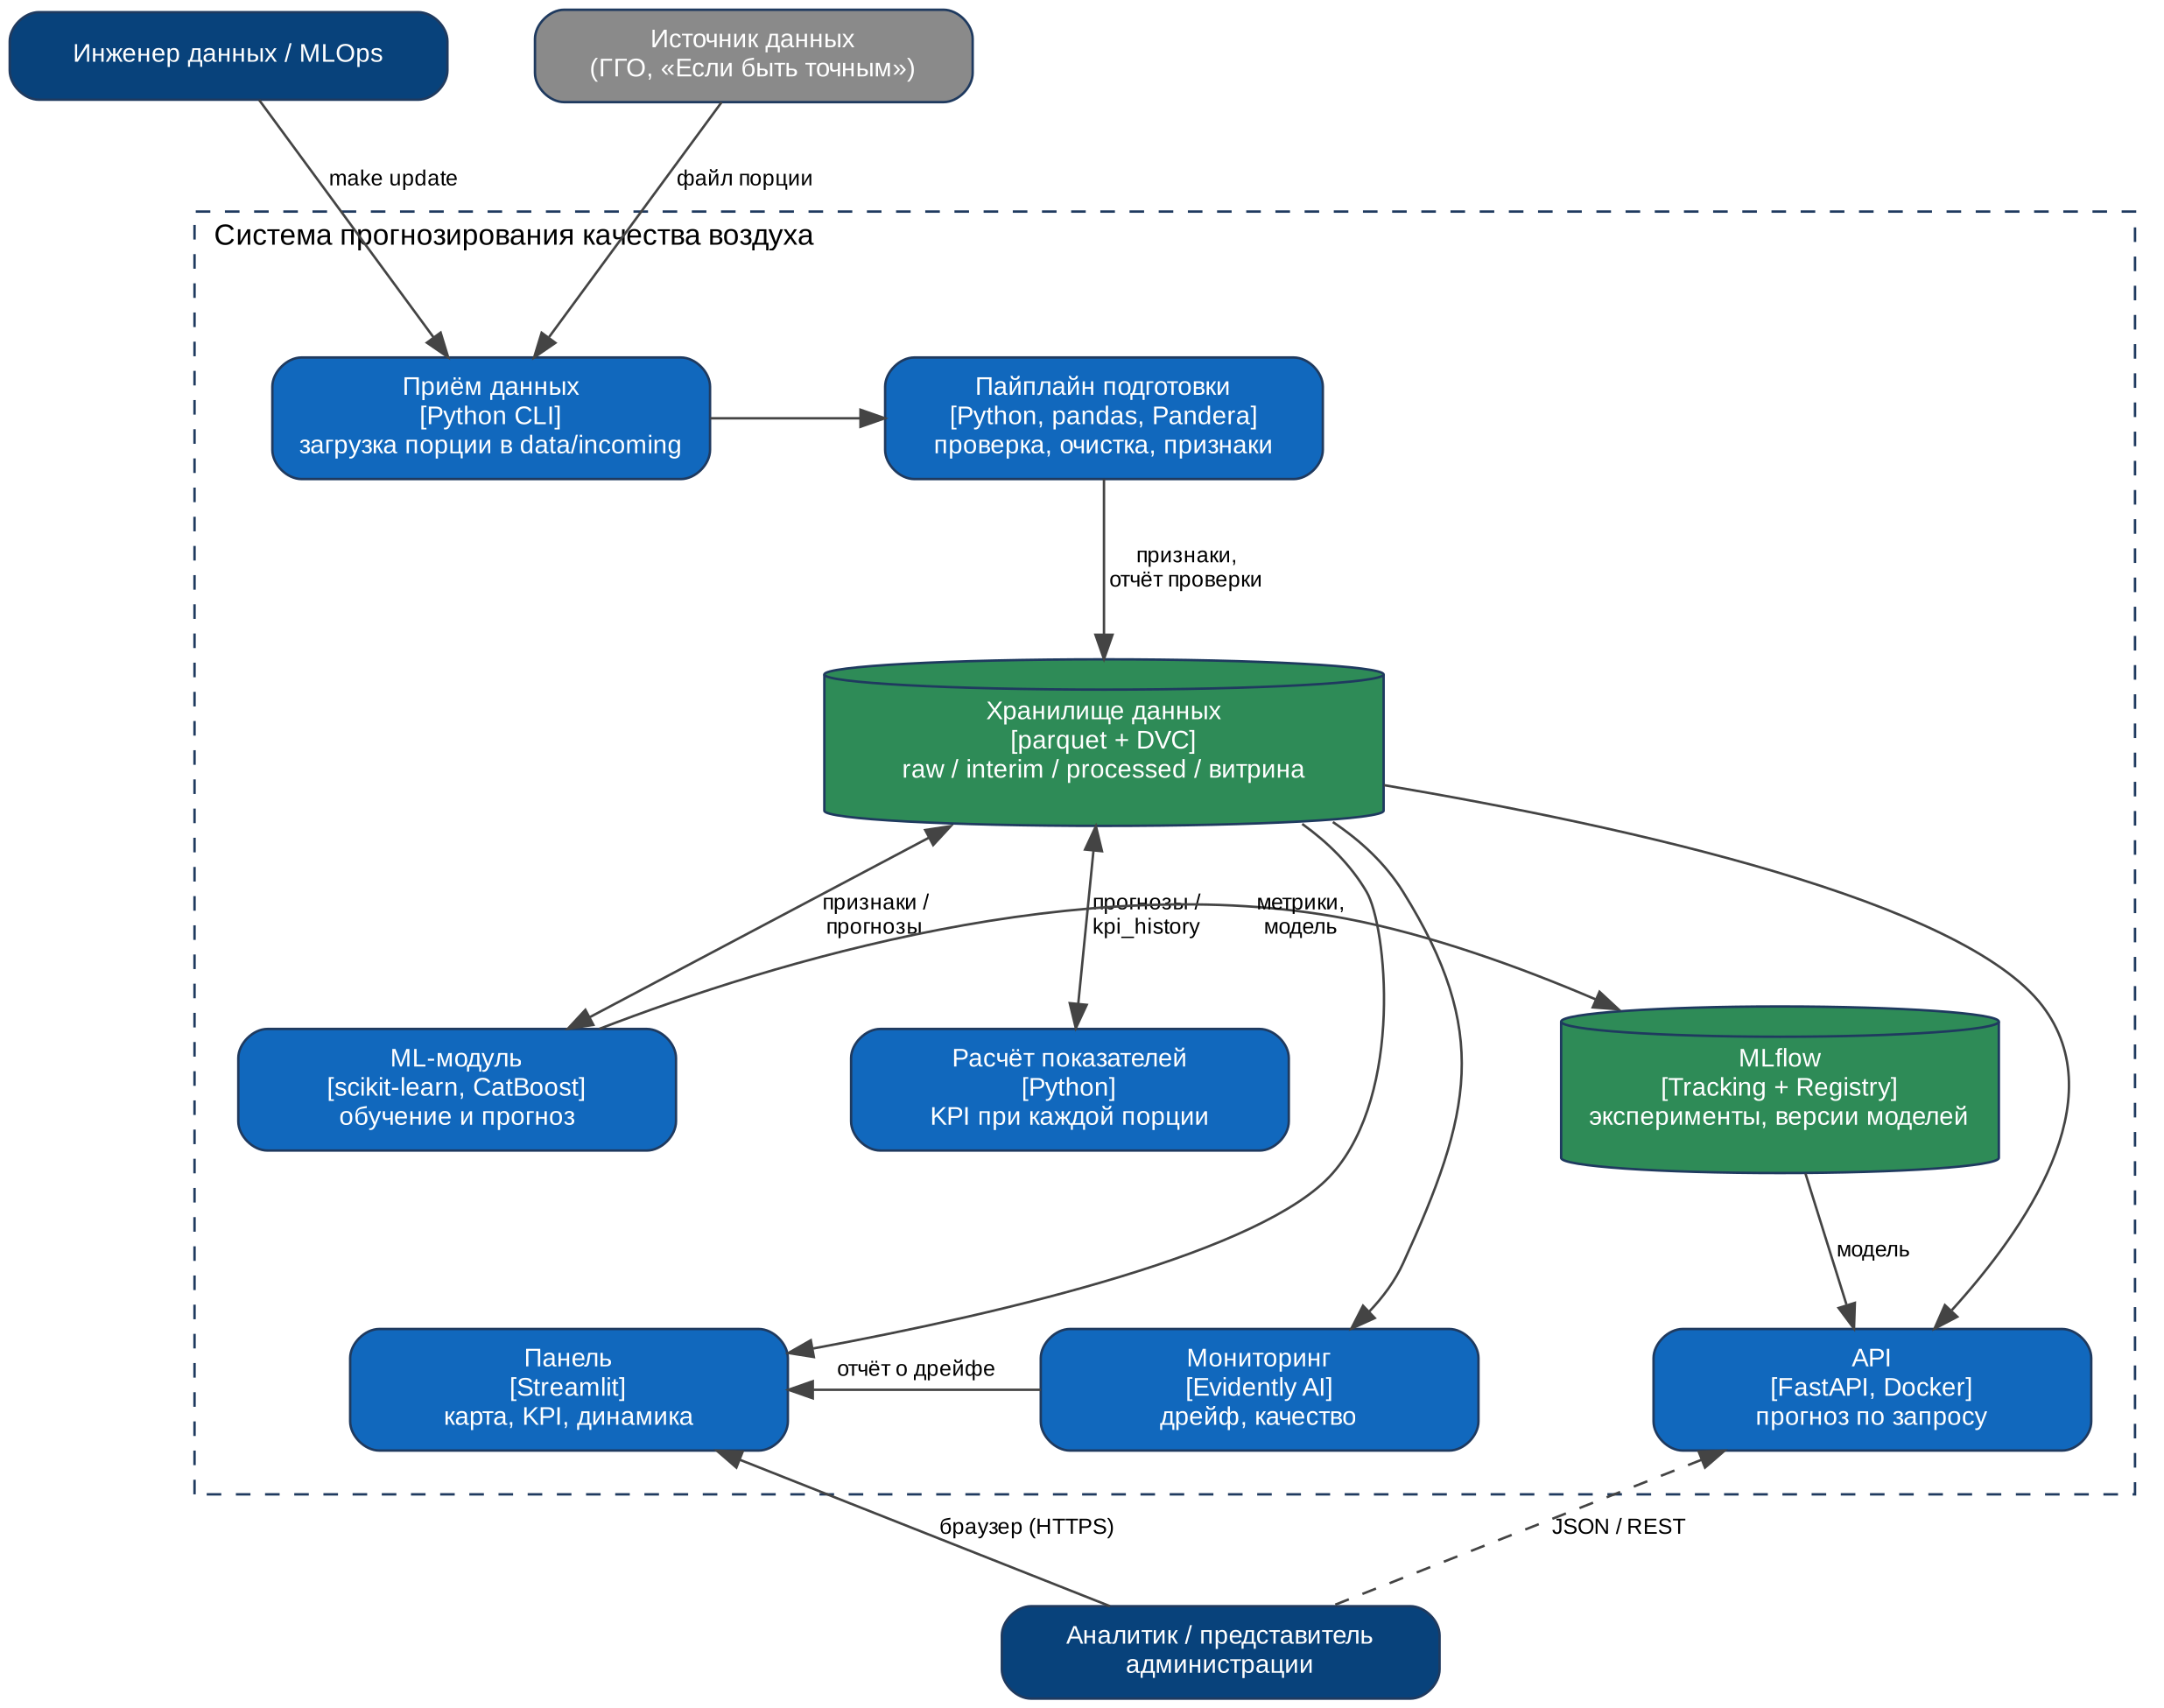

In [21]:
# Рисунок 13. C4, уровень 2: контейнеры
cont = '''digraph G { rankdir=TB; newrank=true; nodesep=0.5; ranksep=0.75; dpi=200;
 node [shape=box, style="rounded,filled", fontname="Liberation Sans", fontsize=10.5, margin="0.15,0.1", color="#1F3A5F", fontcolor=white, fillcolor="#1168BD", width=2.5];
 edge [fontname="Liberation Sans", fontsize=9, color="#444444"];
 dev  [label="Инженер данных / MLOps", fillcolor="#08427B"];
 ggo  [label="Источник данных\n(ГГО, «Если быть точным»)", fillcolor="#8A8A8A"];
 user [label="Аналитик / представитель\nадминистрации", fillcolor="#08427B"];
 subgraph cluster_sys { label="Система прогнозирования качества воздуха"; labeljust=l; fontname="Liberation Sans"; fontsize=12; style="dashed"; color="#1F3A5F"; margin=18;
   ingest [label="Приём данных\n[Python CLI]\nзагрузка порции в data/incoming"];
   pipe   [label="Пайплайн подготовки\n[Python, pandas, Pandera]\nпроверка, очистка, признаки"];
   store  [label="Хранилище данных\n[parquet + DVC]\nraw / interim / processed / витрина", shape=cylinder, fillcolor="#2E8B57", width=3.2];
   ml     [label="ML-модуль\n[scikit-learn, CatBoost]\nобучение и прогноз"];
   kpi    [label="Расчёт показателей\n[Python]\nKPI при каждой порции"];
   mlflow [label="MLflow\n[Tracking + Registry]\nэксперименты, версии моделей", shape=cylinder, fillcolor="#2E8B57"];
   dash   [label="Панель\n[Streamlit]\nкарта, KPI, динамика"];
   mon    [label="Мониторинг\n[Evidently AI]\nдрейф, качество"];
   api    [label="API\n[FastAPI, Docker]\nпрогноз по запросу"];
 }
 {rank=same; dev; ggo}
 {rank=same; ingest; pipe}
 {rank=same; ml; kpi; mlflow}
 {rank=same; dash; mon; api}
 dev -> ingest [label=" make update"]; ggo -> ingest [label=" файл порции"];
 ingest -> pipe; pipe -> store [label=" признаки,\n отчёт проверки"];
 store -> ml [dir=both, label=" признаки /\n прогнозы"]; store -> kpi [dir=both, label=" прогнозы /\n kpi_history"];
 ml -> mlflow [label=" метрики,\n модель"];
 ml -> kpi -> mlflow [style=invis];
 store -> dash; store -> mon; mlflow -> api [label=" модель"]; store -> api [constraint=false];
 mon -> dash [label=" отчёт о дрейфе", constraint=false];
 dash -> mon -> api [style=invis];
 dash -> user [dir=back, label=" браузер (HTTPS)"]; api -> user [dir=back, style=dashed, label=" JSON / REST"];
}'''
render_dot('fig13_c4_containers', cont)

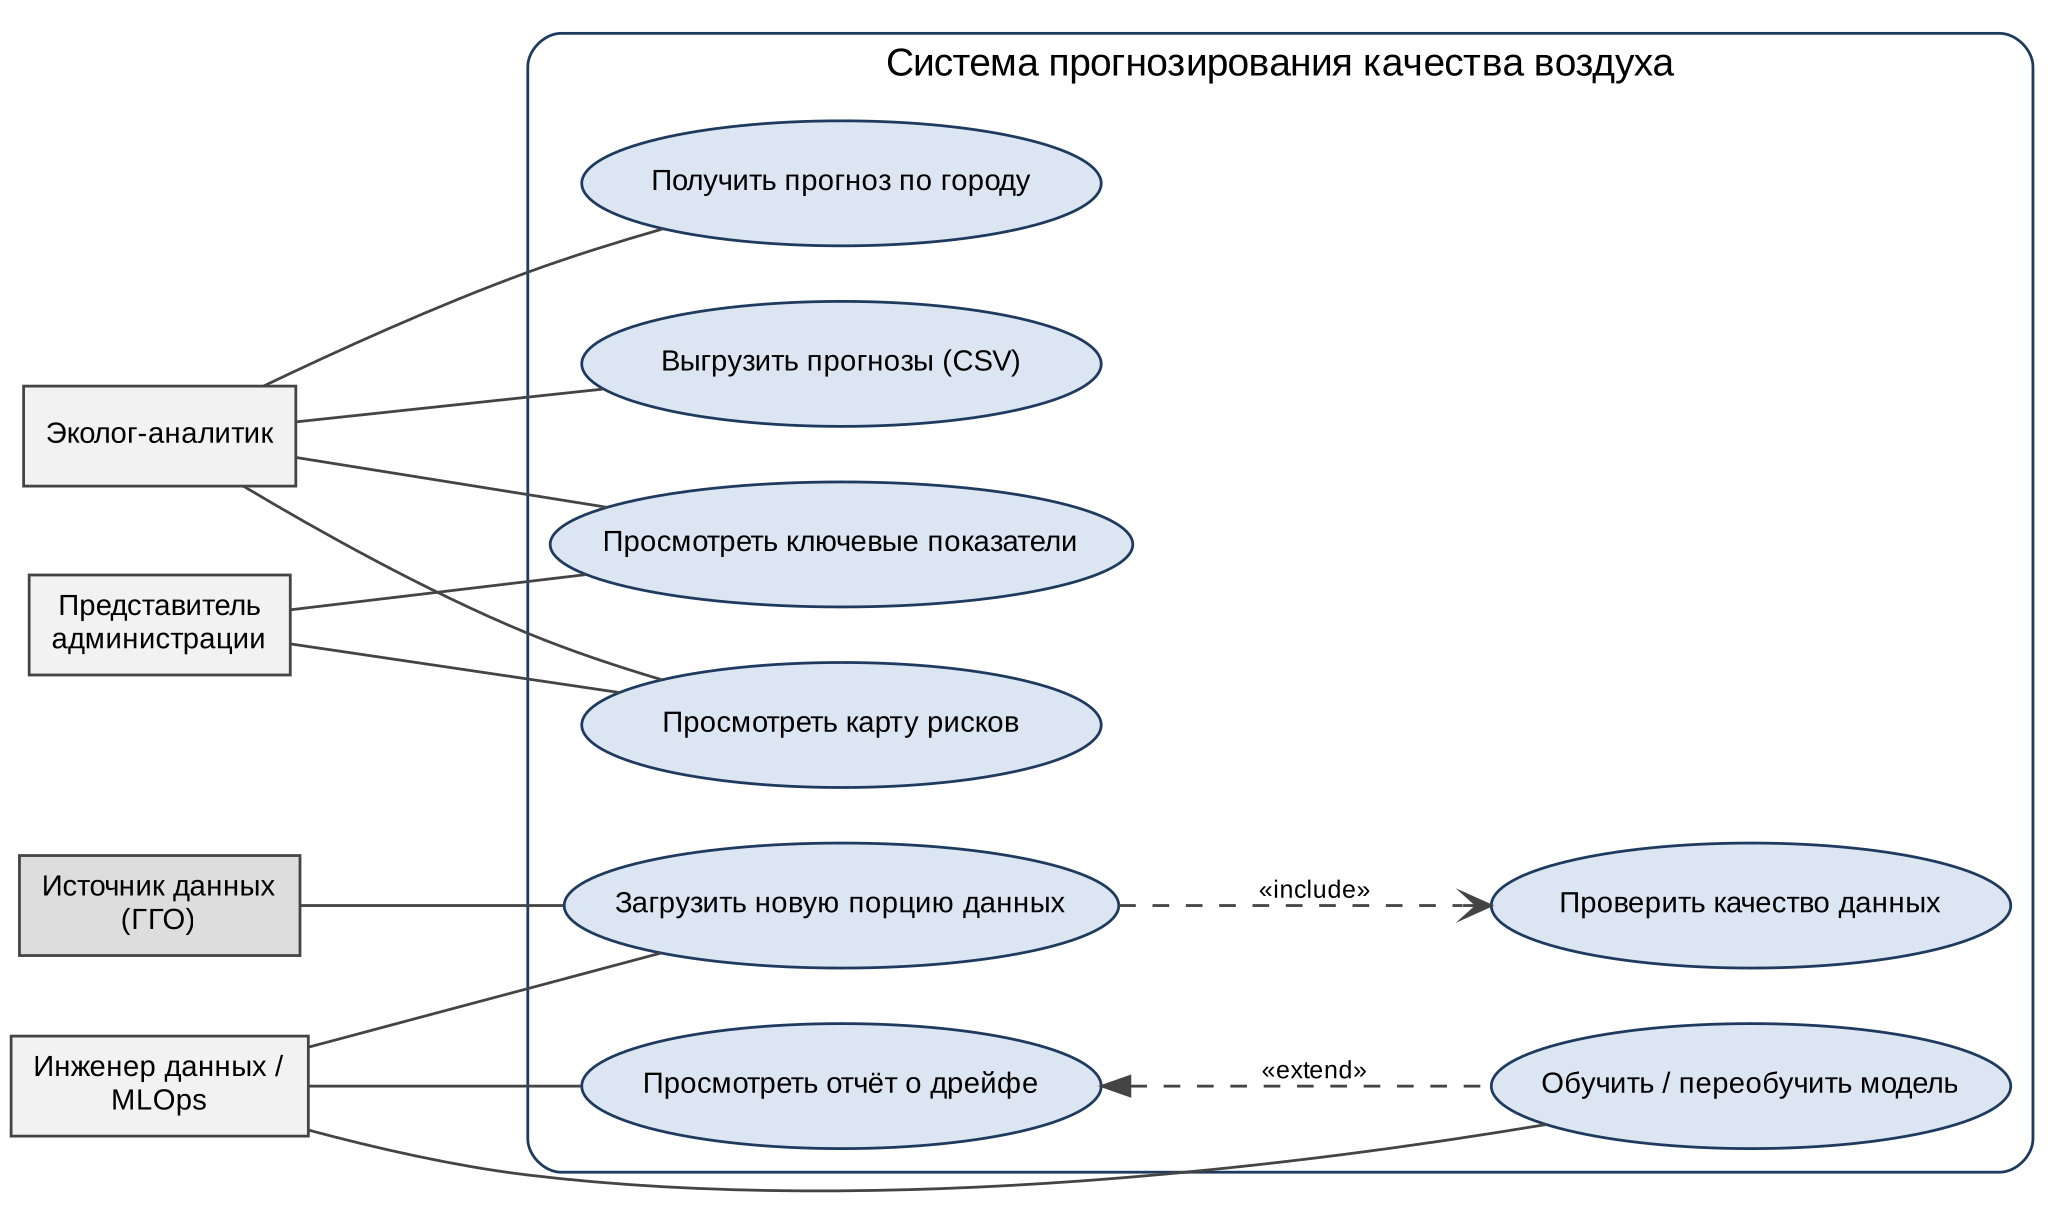

In [22]:
# Рисунок 14. UML: диаграмма вариантов использования
uc = '''digraph G { rankdir=LR; nodesep=0.28; ranksep=1.2; dpi=200; compound=true;
 node [fontname="Liberation Sans", fontsize=10.5];
 edge [fontname="Liberation Sans", fontsize=9, arrowhead=none, color="#444444"];
 node [shape=box, style="filled", fillcolor="#F2F2F2", color="#444444"];
 analyst [label="Эколог-аналитик"]; lpr [label="Представитель\nадминистрации"]; dev [label="Инженер данных /\nMLOps"]; src [label="Источник данных\n(ГГО)", fillcolor="#DDDDDD"];
 subgraph cluster_s { label="Система прогнозирования качества воздуха"; style=rounded; color="#1F3A5F"; fontname="Liberation Sans";
  node [shape=ellipse, style="filled", fillcolor="#DCE6F2", color="#1F3A5F", width=2.6, height=0.62];
  u1 [label="Загрузить новую порцию данных"]; u2 [label="Проверить качество данных"]; u3 [label="Обучить / переобучить модель"];
  u4 [label="Получить прогноз по городу"]; u5 [label="Просмотреть ключевые показатели"]; u6 [label="Просмотреть карту рисков"];
  u7 [label="Просмотреть отчёт о дрейфе"]; u8 [label="Выгрузить прогнозы (CSV)"];
 }
 src -> u1; dev -> u1; dev -> u3; dev -> u7; analyst -> u4; analyst -> u5; analyst -> u6; analyst -> u8; lpr -> u5; lpr -> u6;
 u1 -> u2 [style=dashed, arrowhead=vee, label=" «include»"];
 u7 -> u3 [style=dashed, arrowhead=vee, label=" «extend»", dir=back];
 {rank=same; analyst; lpr; dev; src}
}'''
render_dot('fig14_usecase', uc)

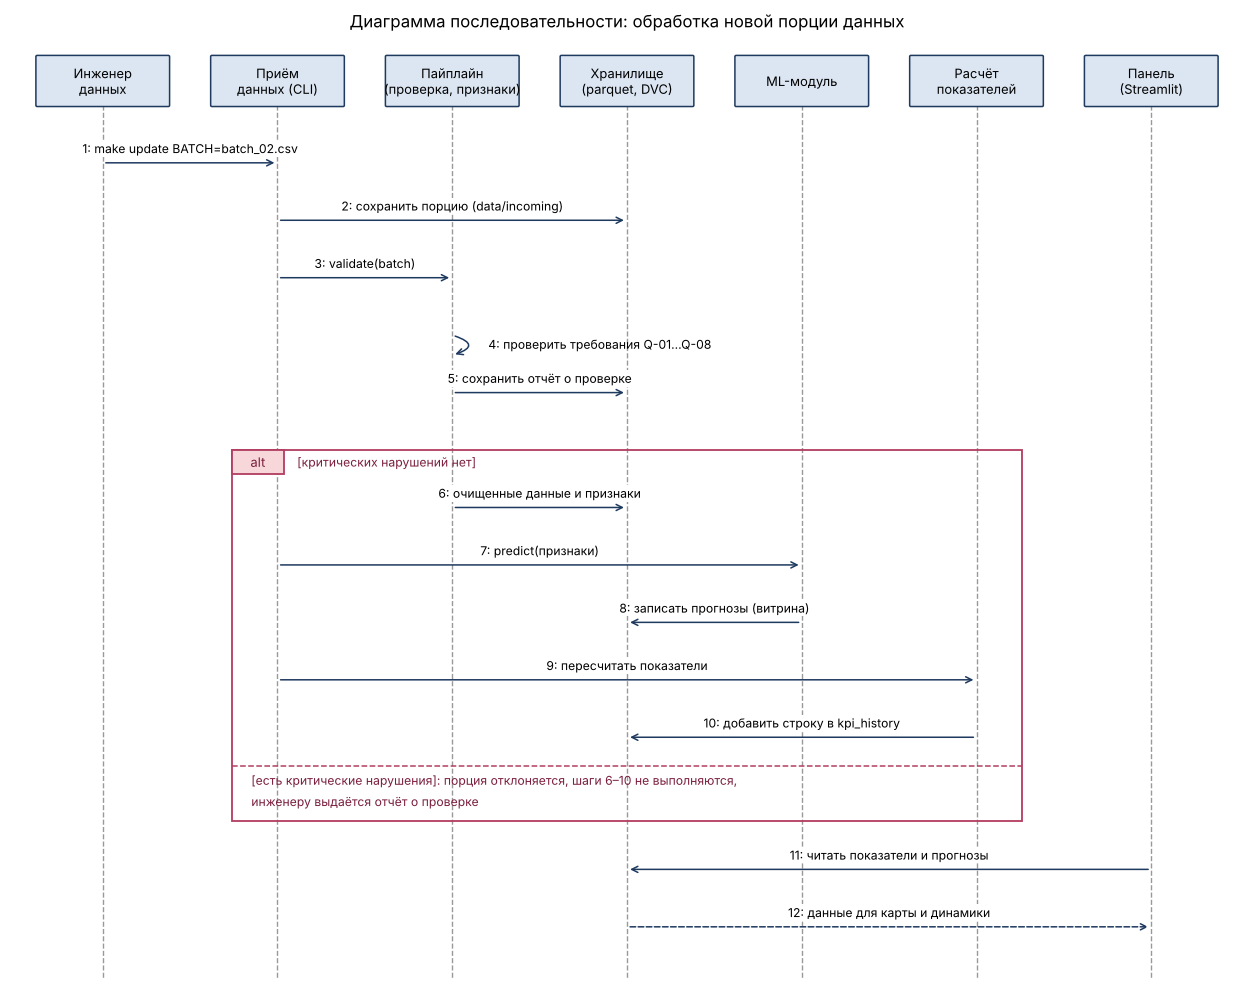

In [23]:
# Рисунок 15. UML: диаграмма последовательности (обработка новой порции)
parts_seq = ['Инженер\nданных', 'Приём\nданных (CLI)', 'Пайплайн\n(проверка, признаки)', 'Хранилище\n(parquet, DVC)', 'ML-модуль', 'Расчёт\nпоказателей', 'Панель\n(Streamlit)']
msgs = [(0, 1, '1: make update BATCH=batch_02.csv', 'sync'), (1, 3, '2: сохранить порцию (data/incoming)', 'sync'),
        (1, 2, '3: validate(batch)', 'sync'), (2, 2, '4: проверить требования Q-01…Q-08', 'self'),
        (2, 3, '5: сохранить отчёт о проверке', 'sync'),
        (2, 3, '6: очищенные данные и признаки', 'sync'),
        (1, 4, '7: predict(признаки)', 'sync'), (4, 3, '8: записать прогнозы (витрина)', 'sync'),
        (1, 5, '9: пересчитать показатели', 'sync'), (5, 3, '10: добавить строку в kpi_history', 'sync'),
        (6, 3, '11: читать показатели и прогнозы', 'sync'), (3, 6, '12: данные для карты и динамики', 'ret')]
n = len(parts_seq); xs = np.linspace(0, 16, n); step = 1.0
ypos = []
for i in range(len(msgs)):
    ypos.append(-(i + 1) * step - (1.3 * step if i >= 10 else 0) - (1.0 * step if i >= 5 else 0))
ybottom = ypos[-1] - 0.9
fig, ax = plt.subplots(figsize=(11.5, 9.2)); ax.set_xlim(-1.4, 17.4); ax.set_ylim(ybottom - 0.2, 1.2); ax.axis('off')
for x, p in zip(xs, parts_seq):
    ax.add_patch(mpatches.FancyBboxPatch((x - 1.0, 0.0), 2.0, 0.85, boxstyle='round,pad=0.02', fc='#DCE6F2', ec='#1F3A5F'))
    ax.text(x, 0.42, p, ha='center', va='center', fontsize=8.5)
    ax.plot([x, x], [0, ybottom], color='#999', lw=0.9, ls='--', zorder=0)
# фрагмент alt (шаги 6–10)
y_top = ypos[5] + 1.0; y_bot = ypos[9] - 0.5; y_else = y_bot - 0.95
x0 = xs[1] - 0.7; x1 = xs[5] + 0.7
ax.add_patch(mpatches.Rectangle((x0, y_else), x1 - x0, y_top - y_else, fc='none', ec='#B33F62', lw=1.2, zorder=1))
ax.add_patch(mpatches.Rectangle((x0, y_top - 0.42), 0.8, 0.42, fc='#F8D7DA', ec='#B33F62', lw=1.2, zorder=1)); ax.text(x0 + 0.4, y_top - 0.21, 'alt', ha='center', va='center', fontsize=8.5, color='#7A1F3D')
ax.text(x0 + 1.0, y_top - 0.21, '[критических нарушений нет]', fontsize=8, color='#7A1F3D', va='center')
ax.plot([x0, x1], [y_bot, y_bot], color='#B33F62', lw=1, ls='--', zorder=1)
ax.text(x0 + 0.3, y_bot - 0.25, '[есть критические нарушения]: порция отклоняется, шаги 6–10 не выполняются,', fontsize=8, color='#7A1F3D', va='center')
ax.text(x0 + 0.3, y_bot - 0.62, 'инженеру выдаётся отчёт о проверке', fontsize=8, color='#7A1F3D', va='center')
for i, (a, b, text, kind) in enumerate(msgs):
    y = ypos[i]
    if kind == 'self':
        ax.annotate('', xy=(xs[a], y - 0.35), xytext=(xs[a], y), arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=-1.6', color='#1F3A5F'))
        ax.text(xs[a] + 0.55, y - 0.16, text, fontsize=8, va='center')
    else:
        ax.annotate('', xy=(xs[b], y), xytext=(xs[a], y), arrowprops=dict(arrowstyle='->', color='#1F3A5F', ls='--' if kind == 'ret' else '-'))
        ax.text((xs[a] + xs[b]) / 2, y + 0.17, text, ha='center', fontsize=8, bbox=dict(fc='white', ec='none', pad=0.6))
if SHOW_TITLES: ax.set_title('Диаграмма последовательности: обработка новой порции данных', fontsize=11)
plt.tight_layout(); plt.savefig(FIG / 'fig15_sequence.png', bbox_inches='tight'); plt.show()

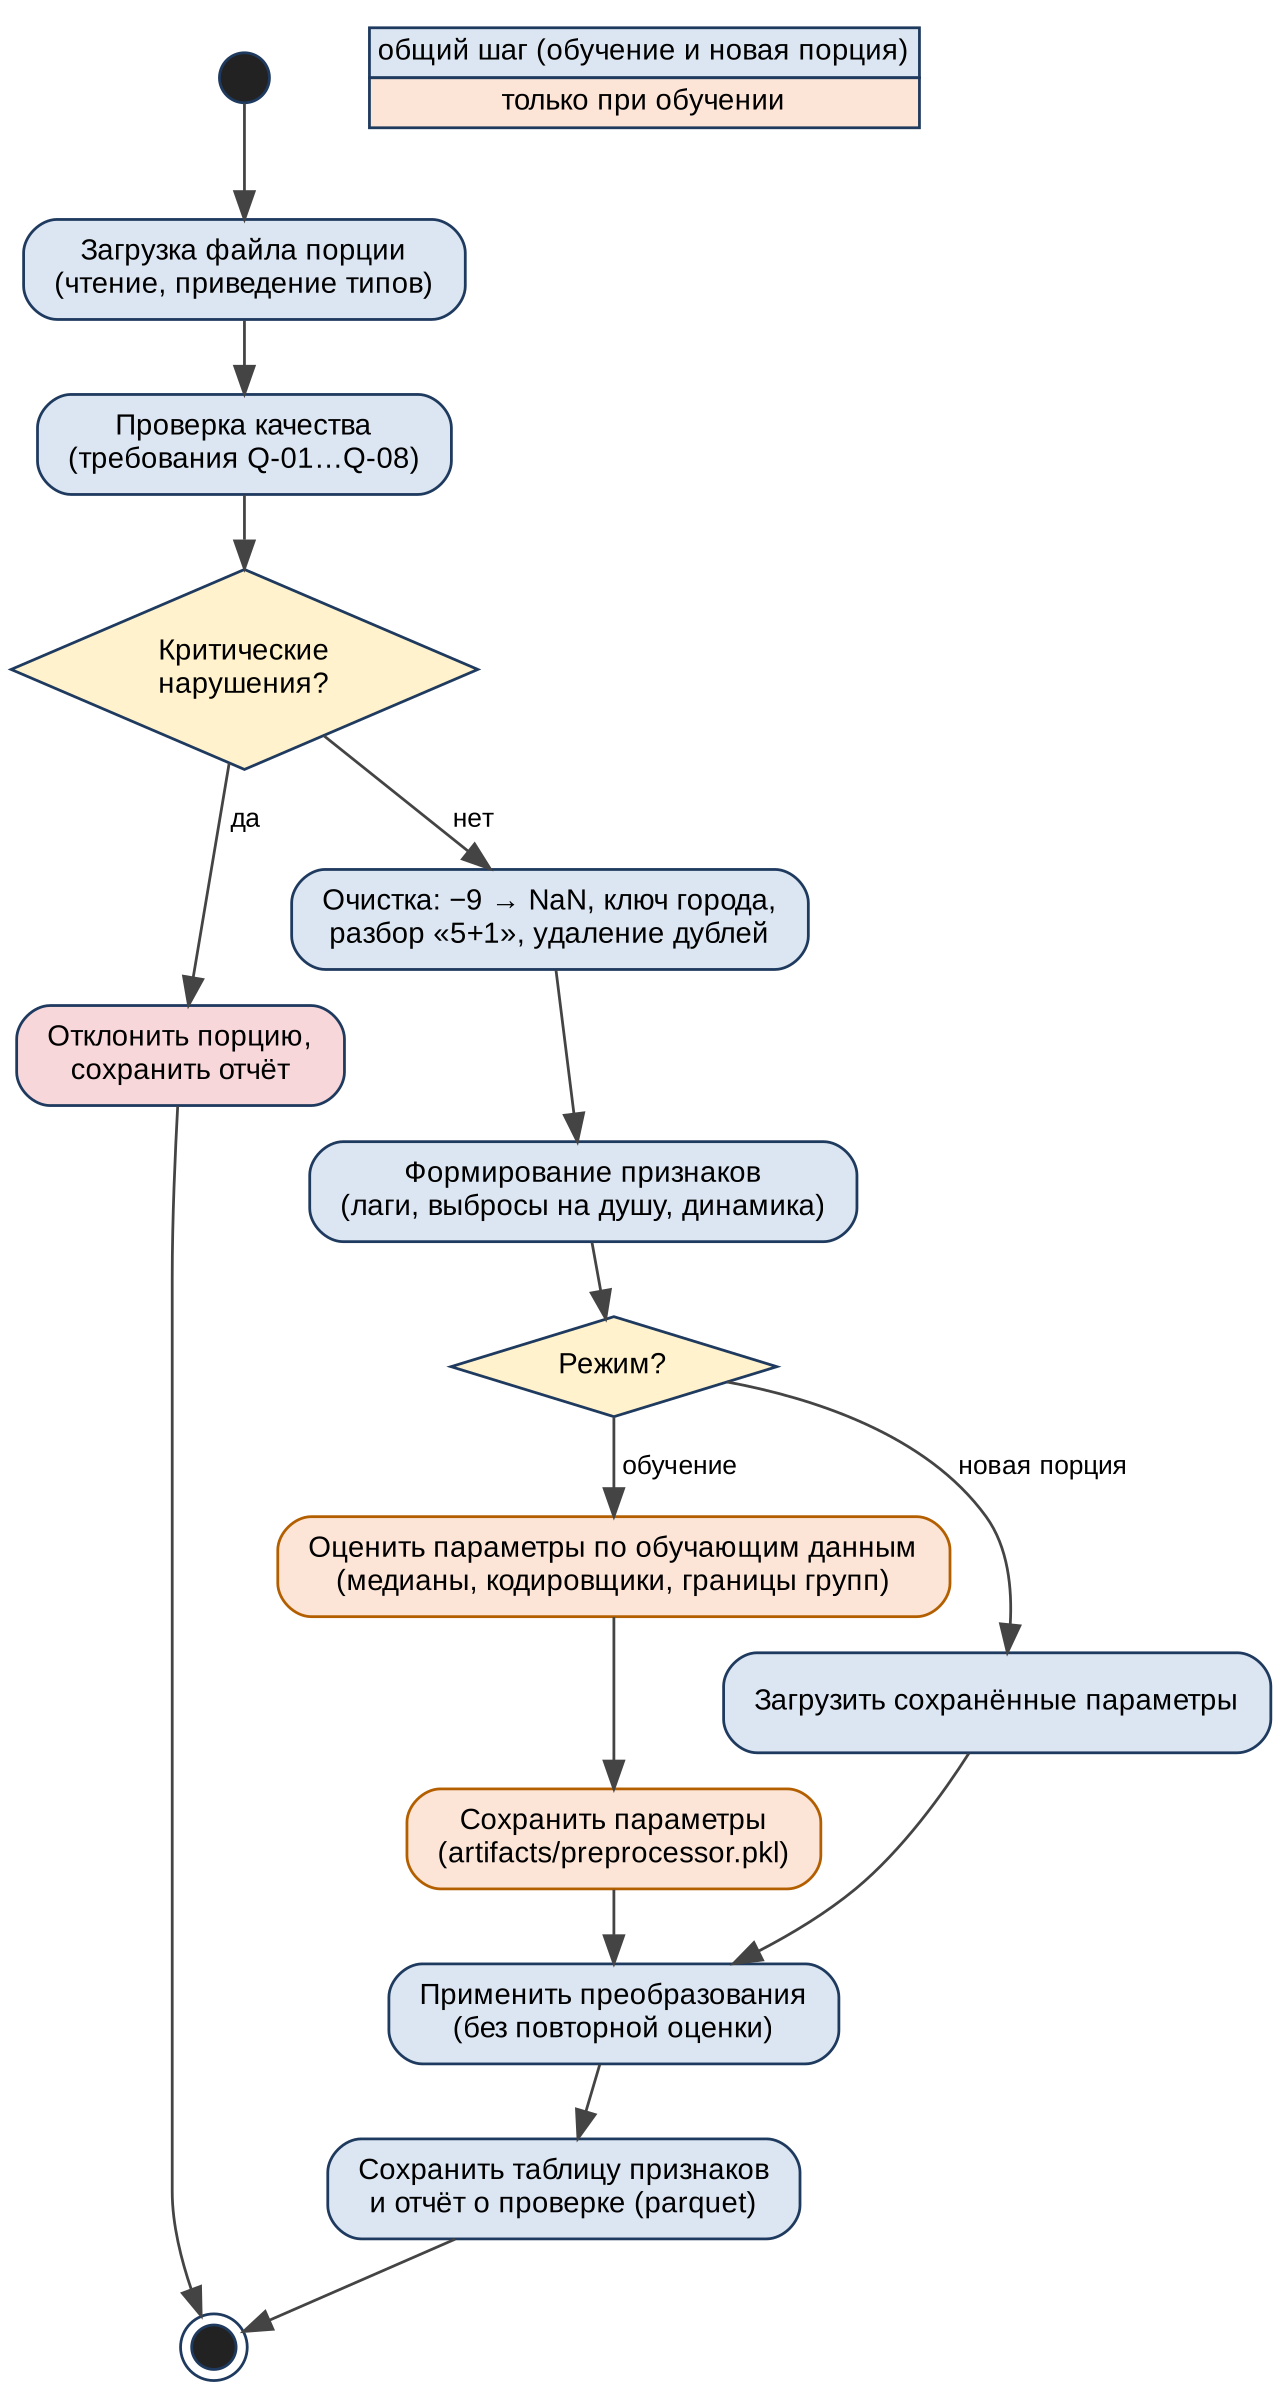

In [24]:
# Рисунок 16. UML: диаграмма деятельности пайплайна (синий — общие шаги, оранжевый — только обучение)
act = '''digraph G { rankdir=TB; nodesep=0.35; ranksep=0.35; dpi=200;
 node [fontname="Liberation Sans", fontsize=10.5, style="rounded,filled", shape=box, fillcolor="#DCE6F2", color="#1F3A5F", margin="0.15,0.08"];
 edge [fontname="Liberation Sans", fontsize=9.5, color="#444444"];
 s [shape=circle, label="", width=0.25, fillcolor="#222222"];
 e [shape=doublecircle, label="", width=0.22, fillcolor="#222222"];
 a1 [label="Загрузка файла порции\n(чтение, приведение типов)"];
 a2 [label="Проверка качества\n(требования Q-01…Q-08)"];
 d1 [shape=diamond, style="filled", label="Критические\nнарушения?", fillcolor="#FFF2CC"];
 stop [label="Отклонить порцию,\nсохранить отчёт", fillcolor="#F8D7DA"];
 a3 [label="Очистка: −9 → NaN, ключ города,\nразбор «5+1», удаление дублей"];
 a4 [label="Формирование признаков\n(лаги, выбросы на душу, динамика)"];
 d2 [shape=diamond, style="filled", label="Режим?", fillcolor="#FFF2CC"];
 t1 [label="Оценить параметры по обучающим данным\n(медианы, кодировщики, границы групп)", fillcolor="#FCE4D6", color="#B35F00"];
 t2 [label="Сохранить параметры\n(artifacts/preprocessor.pkl)", fillcolor="#FCE4D6", color="#B35F00"];
 b1 [label="Загрузить сохранённые параметры"];
 a5 [label="Применить преобразования\n(без повторной оценки)"];
 a6 [label="Сохранить таблицу признаков\nи отчёт о проверке (parquet)"];
 s -> a1 -> a2 -> d1; d1 -> stop [label=" да"]; stop -> e;
 d1 -> a3 [label=" нет"]; a3 -> a4 -> d2;
 d2 -> t1 [label=" обучение"]; t1 -> t2 -> a5;
 d2 -> b1 [label=" новая порция"]; b1 -> a5;
 a5 -> a6 -> e;
 leg1 [shape=plaintext, style="", label=<<table border="0" cellborder="1" cellspacing="0"><tr><td bgcolor="#DCE6F2">общий шаг (обучение и новая порция)</td></tr><tr><td bgcolor="#FCE4D6">только при обучении</td></tr></table>>];
}'''
render_dot('fig16_activity', act)

In [25]:
print('Готово. Файлы рисунков:'); print(*sorted(p.name for p in FIG.glob('*.png')), sep='\n')

Готово. Файлы рисунков:
fig01_split.png
fig02_target.png
fig03_missing.png
fig04_outliers.png
fig05_by_level.png
fig06_corr.png
fig07_leakage.png
fig08_h1_h2.png
fig09_h3.png
fig10_h4.png
fig11_features.png
fig12_c4_context.png
fig13_c4_containers.png
fig14_usecase.png
fig15_sequence.png
fig16_activity.png
